# Getting started with `pyramids-mesh`

`pyramids-mesh` is a **thin file-format layer**. Hydrodynamic and hydraulic solvers each
save their mesh in their own format — Gmsh `.msh`, SMS/TUFLOW `.2dm`, Telemac Selafin, DHI
`.dfsu`, XMDF, and dozens more. `pyramids-mesh` registers a *driver* for each of these formats
whose only job is to **parse the file and hand back a `pyramids.netcdf.ugrid` object**
(a `UgridDataset` wrapping a `Mesh2d` / `Network1d`).

Why does that matter? Because once the mesh is a `pyramids` object, the **entire pyramids GIS
toolbox applies** — bounds, CRS handling, conversion to a `GeoDataFrame`, bounding polygons,
circumcenters, plotting through `cleopatra`, and so on. `pyramids-mesh` adds *readers*, not
geometry algorithms: every mesh operation lives upstream in `pyramids-gis`.

This notebook walks the whole path end to end:

1. the **driver registry** — how formats are discovered,
2. **`UgridDataset.read_file`** — how a file is dispatched to the right driver,
3. a first **read → explore → plot** on one real Gmsh mesh, and
4. a couple of **GIS operations** that come for free from pyramids.

## 1. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
from pyramids.netcdf.ugrid import UgridDataset, mesh_drivers
import numpy as np
import pandas as pd

## 2. Locate the example data

This notebook lives in `docs/examples/`, so the repo-root `examples/data/` folder is two levels
up. Paths inside a notebook are always written **relative to the notebook itself**. We will read a
small Gmsh mesh, `gmsh/insulated-2.2.msh`.

In [2]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "gmsh" / "insulated-2.2.msh"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/gmsh/insulated-2.2.msh'), True)

The tuple above confirms the path resolves (`True`). We now have a real file to feed the package.

## 3. The driver registry

Every supported format is a **driver**, discovered through Python entry points and collected by
`mesh_drivers()`. It returns a plain `dict` mapping a short driver **name** to its driver **class**.
The number of entries is simply how many formats this install can read or write.

In [3]:
drivers = mesh_drivers()
f"{len(drivers)} mesh formats registered"

'48 mesh formats registered'

That count is the breadth of the package in one number: a single install dispatches to *all* of
these formats through one API. Let us look at what a single driver tells us about a format.

## 4. What a driver advertises

Each driver class exposes four descriptive attributes:

- `.name` — the short key used in the registry and for forcing a driver,
- `.long_name` — a human-readable format name,
- `.suffixes` — the file extensions it claims, and
- `.capabilities` — a set of verbs describing *what it can do* with that format.

We inspect the Gmsh driver, since that is the format we are about to read.

In [4]:
gmsh = drivers["gmsh"]
{
    "name": gmsh.name,
    "long_name": gmsh.long_name,
    "suffixes": gmsh.suffixes,
    "capabilities": sorted(gmsh.capabilities),
}

{'name': 'gmsh',
 'long_name': 'Gmsh mesh',
 'suffixes': ('.msh',),
 'capabilities': ['read_mesh']}

The capabilities are the vocabulary to read the whole table next:

- `read_mesh` / `write_mesh` — load or save the **topology** (nodes + faces),
- `read_data` / `write_data` — load or save **field values** attached to the mesh,
- `multi_mesh` — the file can hold more than one mesh, and
- `lazy_data` — field values can be read on demand rather than all at once.

So a format tagged only `read_mesh` gives you geometry but no solver results — exactly the Gmsh case.

## 5. The full format table

Capabilities and suffixes for *every* registered driver make a natural DataFrame. Rendering it as a
table is the clearest way to see the plugin's reach at a glance — which formats are read-only, which
can round-trip data, which carry multiple meshes.

In [5]:
rows = [
    {
        "name": d.name,
        "long_name": d.long_name,
        "suffixes": ", ".join(d.suffixes),
        "capabilities": ", ".join(sorted(d.capabilities)),
    }
    for d in drivers.values()
]
driver_table = pd.DataFrame(rows).sort_values("name").reset_index(drop=True)
driver_table

,name,long_name,suffixes,capabilities
0,2dm,SMS/TUFLOW 2DM mesh,.2dm,"multi_mesh, read_data, read_mesh, write_data, ..."
1,3di,3Di results,.nc,"lazy_data, read_data, read_mesh"
2,abaqus,Abaqus keyword deck,.inp,read_mesh
3,adcirc,ADCIRC,.14,"lazy_data, read_data, read_mesh"
4,avsucd,AVS-UCD unstructured cell data,".inp, .avs",read_mesh
5,cgns,CGNS/HDF5,.cgns,read_mesh
6,dat,SMS ASCII DAT results,.dat,"needs_mesh, read_data, write_data, write_mesh"
7,deltares1d,Deltares 1D network (Delft3D FM / D-HYDRO),.nc,"lazy_data, read_data, read_mesh"
8,dfsu,DHI MIKE DFSU,.dfsu,"lazy_data, read_data, read_mesh"
9,esmf,ESMF unstructured mesh,.nc,read_mesh


Scanning the `capabilities` column: most drivers are importers (`read_mesh`), a solid subset also
round-trips field data (`read_data` + `write_data`), and only a handful advertise `multi_mesh` or
`lazy_data`. This single table is what "supports N formats" actually means in code.

## 6. Reading a file: automatic dispatch

`UgridDataset.read_file(path)` is the one entry point you normally call. It inspects the file's
**suffix and content**, finds the matching driver in the registry, and runs it — you do not name a
driver yourself. The result is a `UgridDataset`.

In [6]:
ds = UgridDataset.read_file(mesh_file)
type(ds)

pyramids.netcdf.ugrid.dataset.UgridDataset

`read_file` saw the `.msh` suffix, routed to the `gmsh` driver, and returned a fully-formed
`UgridDataset` — the same type pyramids produces from a NetCDF UGRID file. From here on, nothing in
the API knows or cares that the data originated as Gmsh.

## 7. Forcing a specific driver

When a suffix is ambiguous (several formats share `.inp` or `.nc`, for instance) you can override
auto-detection with the `driver=` argument, naming any key from the registry. Here we force `gmsh`
explicitly and confirm we get the identical mesh.

In [7]:
ds_forced = UgridDataset.read_file(mesh_file, driver="gmsh")
ds.n_face == ds_forced.n_face

True

Same face count — forcing the driver produced the same result as auto-detection. The `driver=`
escape hatch is there for the ambiguous-suffix cases, not needed for a clear one like `.msh`.

## 8. Exploring the dataset's metadata

A `UgridDataset` exposes summary properties that describe the mesh as a whole. The most useful on a
first look:

- `n_node` / `n_face` — size of the mesh,
- `crs` / `epsg` — the coordinate reference system, if the format recorded one,
- `bounds` — the spatial extent `(minx, miny, maxx, maxy)`, and
- `data_variable_names` — names of any field variables attached to the mesh.

In [8]:
pd.Series(
    {
        "n_node": ds.n_node,
        "n_face": ds.n_face,
        "crs": ds.crs,
        "epsg": ds.epsg,
        "bounds": ds.bounds,
        "data_variable_names": ds.data_variable_names,
    }
)

n_node                                                                67
n_face                                                               111
crs                                                                 None
epsg                                                                None
bounds                 (-2.96649247971263, -2.991611391173865, 3.0, 2...
data_variable_names                                                   []
dtype: object

Two things stand out. First, `crs`/`epsg` are `None`: the Gmsh format stores raw coordinates with
**no georeferencing**, so pyramids correctly reports an unknown CRS — you would assign one yourself
if you knew it. Second, `data_variable_names` is empty: this file carries **geometry only**, no
solver fields. That is typical of a mesh-generator output.

## 9. File-level attributes

Formats can also carry free-form metadata, surfaced as a dict on `.global_attributes`.

In [9]:
ds.global_attributes

{'source': 'Gmsh'}

Here the driver recorded only the `source` of the mesh. Richer formats (solver outputs) populate
this with run metadata, units, and provenance.

## 10. A statistical summary of the fields

`.summary()` returns a DataFrame of per-variable statistics (count, min, max, mean, std). Because
this mesh has no data variables yet, the summary is **empty** — a useful confirmation, not an error.
We will populate it shortly.

In [10]:
ds.summary()

,count,min,max,mean,std
variable,,,,,


An empty frame with the right columns means "no fields to summarise". Once we attach a variable in
section 14 this same call will report real statistics.

## 11. The underlying `Mesh2d`

`ds.mesh` is the `Mesh2d` object holding the raw topology. The arrays you reach for most often:

- `node_x` / `node_y` — node coordinates,
- `face_node_connectivity.data` — the `(n_face, k)` table of node indices per face, and
- `face_areas` — area of each face.

In [11]:
mesh = ds.mesh
conn = mesh.face_node_connectivity.data
{
    "n_node": mesh.node_x.shape[0],
    "connectivity_shape": conn.shape,
    "face_areas_shape": np.asarray(mesh.face_areas).shape,
}

{'n_node': 67, 'connectivity_shape': (111, 3), 'face_areas_shape': (111,)}

The connectivity shape `(n_face, k)` is the heart of an unstructured mesh: row *i* lists the node
indices that form face *i*. The second dimension `k` is the max nodes per face (triangles pad unused
slots). Everything geometric — areas, centroids, the outline — is derived from this table plus the
node coordinates.

## 12. First plot: the mesh outline

The simplest visualization needs no data at all -- just draw the wireframe with
`plot_outline()`, which renders the mesh edges through `cleopatra` and returns a `MeshGlyph`
wrapping the figure. Reading the file above flipped matplotlib to a non-interactive backend,
so we let cleopatra choose it with `Config.set_matplotlib_backend()` (which picks `inline` in a
notebook); from now on every plot embeds on its own.

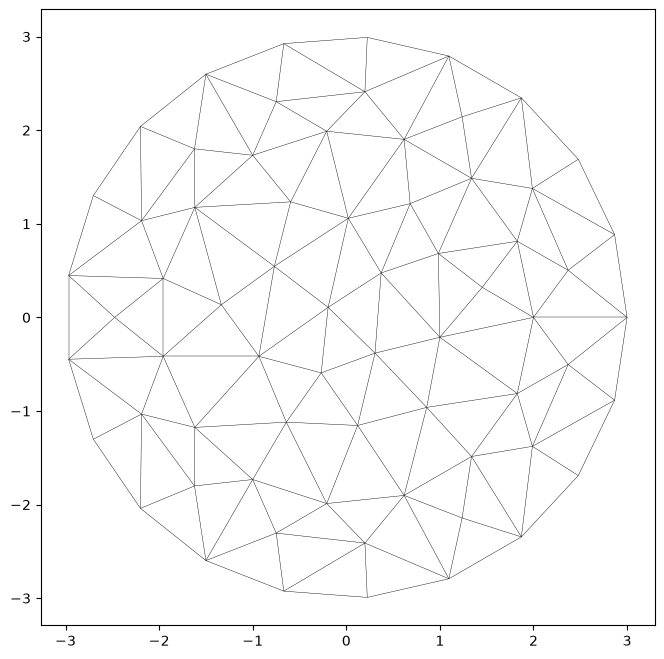

In [12]:
from cleopatra.config import Config
Config.set_matplotlib_backend()  # cleopatra picks the inline backend in a notebook
ds.plot_outline()

This is the mesh *as the solver sees it* — an unstructured grid of triangular cells, finer where the
geometry demands resolution. Seeing the wireframe is the fastest sanity check that a file read in
correctly.

## 13. A data map: attach and plot a field

To draw a *filled* map we need a value per cell. This mesh has none, so we compute one — each cell's
area — and attach it with `with_variable(..., location="face")`, which returns a **new** dataset
carrying that field. (The original `ds` is left untouched.)

In [13]:
d2 = ds.with_variable("cell_area", np.asarray(mesh.face_areas), location="face")
d2.data_variable_names

['cell_area']

`d2` now has a face-located variable called `cell_area`. Because it is a normal pyramids field, we
can colour the mesh by it.

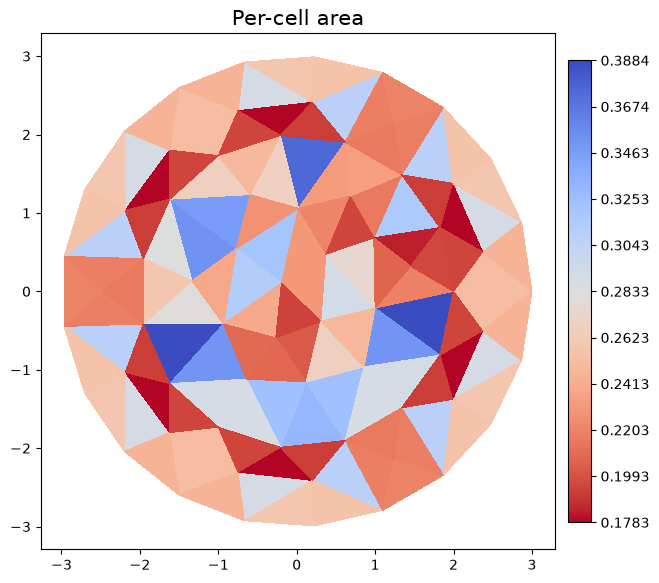

In [14]:
d2.plot("cell_area", cmap="viridis", title="Per-cell area")

Each cell is now shaded by its area: darker cells are smaller (the refined regions), brighter cells
larger (the coarse interior). This is the generic pyramids data-map path — any per-cell field, from
water depth to velocity, plots the same way.

## 14. The summary, now populated

With a field attached, `.summary()` on `d2` reports real statistics — the same call that was empty
in section 11.

In [15]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
cell_area,111,0.178301,0.38836,0.25094,0.049831


The row for `cell_area` gives count (one per face), the min/max cell sizes, and the mean — a quick
numeric companion to the colour map above.

## 15. GIS operations, for free

Because the mesh is a pyramids object, pyramids' GIS layer applies directly. A few teasers:

`bounds` is the extent, and `bounding_polygon()` returns the extent as a shapely `Polygon` you can
intersect, buffer, or export.

In [16]:
poly = ds.bounding_polygon()
{"bounds": ds.bounds, "bounding_polygon_type": type(poly).__name__}

{'bounds': (-2.96649247971263, -2.991611391173865, 3.0, 2.991611391889027),
 'bounding_polygon_type': 'Polygon'}

The bounding polygon is an ordinary shapely geometry — the gateway to the whole shapely/geopandas
ecosystem for clipping and spatial joins.

### Faces as a GeoDataFrame

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard
vector structure for export to shapefile/GeoPackage or for joining against other spatial layers.

In [17]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((-0.19413 0.10715, 0.02141 1.05898, -..."
1,"POLYGON ((-0.93395 -0.41582, -0.19413 0.10715,..."
2,"POLYGON ((0.02141 1.05898, -0.19413 0.10715, 0..."
3,"POLYGON ((-1.9563 -0.41582, -1.61803 -1.17557,..."
4,"POLYGON ((0.61803 1.90211, -0.20906 1.98904, 0..."


One row per face, each with its cell polygon in the `geometry` column. Note the GeoDataFrame's CRS is
unset here — it inherits the mesh's `None` CRS, which you would assign before exporting.

### Circumcenters

`circumcenters()` returns an `(n_face, 2)` array of per-cell circumcenter coordinates — the points a
finite-volume scheme places unknowns at. It is a mesh-derived geometry pyramids computes on demand.

In [18]:
cc = np.asarray(ds.circumcenters())
cc.shape, cc[:3]

((111, 2),
 array([[-0.25617308,  0.62151923],
        [-0.70061175,  0.03886316],
        [-0.10250116,  0.58672018]]))

`(n_face, 2)` — one `(x, y)` per cell. That these derived quantities are a method call away is the
whole point of turning the file into a pyramids object.

## Takeaway

- `pyramids-mesh` is a **format layer**: drivers parse mesh files into `pyramids.netcdf.ugrid`
  objects, and that is all they do — no GIS, no interpolation, no analysis.
- `mesh_drivers()` is the **registry** of every supported format, each driver advertising its
  `suffixes` and `capabilities`.
- `UgridDataset.read_file(path)` **auto-dispatches** to the right driver by suffix/content, with
  `driver=` as an override.
- Once read, the mesh is a first-class pyramids object: explore it (`n_node`, `bounds`, `summary()`),
  plot it (`plot_outline`, `plot`), and run **GIS operations** (`to_geodataframe`, `bounding_polygon`,
  `circumcenters`) — all from pyramids, not from this package.

**Next:** see the per-format and domain notebooks in `docs/examples/` for reading specific solver
outputs (2DM, Selafin, DFSU, …), attaching real result fields, and the deeper GIS workflows pyramids
provides.